# MLP_JK_04 — Random-neighbor control: do the real neighbors matter?

**The question (asked by the professor):** in MLP_JK_03, adding the 3×3 neighborhood average to the center spot (setup D) lowered the test loss compared with the center spot alone (setup A). Does that gain come from the **real neighbors**, or would averaging in **any** extra embeddings do the same?

Everything is the same as MLP_JK_03 setup D: center PCA 256 + PCA 256 of a neighborhood average = 512 inputs, hidden 128, dropout 0.3, weight decay 1e-3, lr 3e-4, early stopping, shrinkage `k` chosen on validation (4 inner patient groups), retrain on all training patients, 3 model seeds averaged. **The only thing that changes is which spots go into the "neighbor" average.**

| Setup | Spots averaged with the center | What it keeps |
|---|---|---|
| **A** center only | none (256 inputs) | reference |
| **D** real 3×3 | the real 3×3 neighbors | local tissue, same slide, same patient |
| **R1** random, same section | random spots from the **same section** | same slide and patient, but not local |
| **R2** random, other patients | random spots from **other patients** in the same split | neither slide nor patient; only "averaging more embeddings" |

For R1 and R2, every spot gets **the same number** of random spots as its real 3×3 neighborhood has (edge spots have fewer), so only *which* spots changes, not *how many*.

**How to read it (decided before running)**
1. D clearly better than R1 → the **local** neighborhood really matters.
2. R1 better than A → part of the gain is **slide/patient-level** information (a section average tells the model something about the whole slide).
3. R2 better than A → part of the gain is **just from averaging** extra embeddings (e.g. smoothing out noise in the center embedding).

A difference only counts if it's larger than the spread across random draws and model seeds, and holds in most folds.

**Checks**
- Ridge on raw embeddings must reproduce Notebook 5 (pooled PCC 0.187).
- Setup D runs first and must reproduce MLP_JK_03's setup D (test MSE ≈ 0.958, pooled PCC ≈ 0.206), or the notebook stops.

This is a control experiment, so it does **not** update MLP_JK_Best.

**Reads** `~/JHU/BDD/datasets/BDD_HEST`, Notebook 5's scores in `~/JHU/BDD/Experiments/smoothing_control/`, and `~/JHU/BDD/MLP_JK/results/MLP_JK_03/`.
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_04/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores (ridge check).
- `REFERENCE_DIR`: MLP_JK_03's saved scores, for the reference rows (setups A and D) and the setup D check.
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5): `N_FOLDS`, `N_GENES`, `MIN_TEST_SD`, `SEED`, and the ridge settings `N_INNER_FOLDS`, `ALPHAS`.

**Inputs**
- `SETUPS`: which setups to run (see the table above).
- `NEIGHBOR_DISTANCE = 1.8` spot spacings = the 3×3 square (as in Notebook 5).
- `N_PCS = 256`: PCA size for the center and for each neighborhood average.
- `DRAW_SEEDS`: the random draws of neighbors for R1 and R2. Each draw is a full, separate run, so we can see how much the result depends on which random spots were picked.

**MLP** (fixed, the same as MLP_JK_03): `HIDDEN_SIZE`, `DROPOUT`, `WEIGHT_DECAY`, `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`, `SHRINK_FACTORS` (`k` values), `N_VAL_GROUPS` (validation groups of training patients), `N_FINAL_SEEDS` (model seeds).

**Setup D check**: how far setup D may be from MLP_JK_03's setup D before the notebook stops. It's the same pipeline, so it should match closely.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
REFERENCE_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_03")
NOTEBOOK_NAME = "MLP_JK_04"
LOG_RESULTS = True
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

SETUPS = ["A", "D", "R1", "R2"]
NEIGHBOR_DISTANCE = 1.8
N_PCS = 256
DRAW_SEEDS = [0, 1, 2]

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_PCC_TOLERANCE = 0.01
CHECK_MSE_TOLERANCE = 0.005

Names of the setups, the reference rows from MLP_JK_03, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

`RUNS` lists every model that gets trained: A and D once, and R1 and R2 once per random draw.

In [3]:
SETUP_NAMES = {
    "A": "A center only",
    "D": "D real 3x3",
    "R1": "R1 random same section",
    "R2": "R2 random other patients",
}
INPUT_SIZES = {"A": N_PCS, "D": 2 * N_PCS, "R1": 2 * N_PCS, "R2": 2 * N_PCS}
REFERENCE_ROWS = {"A center only": "MLP_JK_03 A (logged)", "D 3x3 average": "MLP_JK_03 D (logged)"}

RUNS = []
for setup in SETUPS:
    if setup in ["R1", "R2"]:
        for draw in range(len(DRAW_SEEDS)):
            RUNS.append({"name": f"{setup} draw {draw}", "setup": setup, "draw": draw})
    else:
        RUNS.append({"name": setup, "setup": setup, "draw": None})
print("Runs:", [run["name"] for run in RUNS])

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Runs: ['A', 'D', 'R1 draw 0', 'R1 draw 1', 'R1 draw 2', 'R2 draw 0', 'R2 draw 1', 'R2 draw 2']
Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Real 3×3 neighborhoods (same definition as Notebook 5)

For each section, the spot spacing = median distance from a spot to its closest other spot. A spot's neighborhood = every spot on the same section within 1.8 spacings (the 3×3 square), **including the spot itself**. Edge spots have fewer neighbors and are averaged over what exists.

The size of each real neighborhood is also what decides how many random spots R1 and R2 get.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


real_neighborhoods = find_neighborhoods(NEIGHBOR_DISTANCE)
neighbor_counts = np.array([len(n) - 1 for n in real_neighborhoods])
print(f"Real 3x3: neighbors per spot (not counting itself) mean {neighbor_counts.mean():.2f}, "
      f"min {neighbor_counts.min()}, max {neighbor_counts.max()}")
print("Spots by number of neighbors:")
print(pd.Series(neighbor_counts).value_counts().sort_index().to_string())

Real 3x3: neighbors per spot (not counting itself) mean 7.30, min 0, max 9
Spots by number of neighbors:
0        4
1       26
2       77
3      371
4     1291
5     2534
6     1367
7     3284
8    21643
9        3


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

In [7]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

In [8]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


In [9]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. Random neighbors for R1 and R2

Each spot keeps its own embedding as the center of the average, plus **as many random spots as its real 3×3 neighborhood has** (0 to 9 here). The random spots are drawn without repeats and never include the spot itself.

- **R1, same section**: random spots from the spot's own section. They share the slide and the patient, but not the location.
- **R2, other patients**: random spots from *other* patients on the same side of the split. Training spots draw from other training patients, and test spots from other test-fold patients, so no test embedding ever enters a training spot's average (or the other way round). This depends on the fold, so R2 is drawn separately for each fold.

The draws use only the spot table (sections, patients, folds), never expression, so no labels are involved. Each draw seed gives a different, reproducible set of random neighbors.

In [10]:
def random_same_section(draw_seed):
    rng = np.random.default_rng(draw_seed)
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        for row in rows:
            pool = rows[rows != row]
            chosen = rng.choice(pool, size=neighbor_counts[row], replace=False)
            neighborhoods[row] = np.concatenate([[row], chosen])
    return neighborhoods


def random_other_patients(draw_seed, fold):
    rng = np.random.default_rng([draw_seed, fold])
    is_test = fold_of_spot == fold
    neighborhoods = [None] * len(spots)
    for patient in np.unique(patient_array):
        patient_rows = np.where(patient_array == patient)[0]
        same_side = is_test == is_test[patient_rows[0]]
        pool = np.where(same_side & (patient_array != patient))[0]
        for row in patient_rows:
            chosen = rng.choice(pool, size=neighbor_counts[row], replace=False)
            neighborhoods[row] = np.concatenate([[row], chosen])
    return neighborhoods


example_r1 = random_same_section(DRAW_SEEDS[0])
example_r2 = random_other_patients(DRAW_SEEDS[0], 0)
for name, neighborhoods in [("R1", example_r1), ("R2 (fold 0)", example_r2)]:
    counts = np.array([len(n) - 1 for n in neighborhoods])
    assert np.array_equal(counts, neighbor_counts), f"{name}: counts differ from the real neighborhoods"
    same_section = np.mean([np.all(section_array[n] == section_array[n[0]]) for n in neighborhoods])
    other_patient = np.mean([np.all(patient_array[n[1:]] != patient_array[n[0]]) for n in neighborhoods])
    print(f"{name}: same number of neighbors as the real 3x3 for every spot | "
          f"all neighbors on the same section: {same_section:.1%} | all neighbors from other patients: {other_patient:.1%}")

is_test = fold_of_spot == 0
crosses_split = np.mean([np.any(is_test[n[1:]] != is_test[n[0]]) for n in example_r2])
print(f"R2 (fold 0): spots whose random neighbors cross the train/test split: {crosses_split:.1%}")
del example_r1, example_r2

R1: same number of neighbors as the real 3x3 for every spot | all neighbors on the same section: 100.0% | all neighbors from other patients: 0.0%
R2 (fold 0): same number of neighbors as the real 3x3 for every spot | all neighbors on the same section: 0.0% | all neighbors from other patients: 100.0%
R2 (fold 0): spots whose random neighbors cross the train/test split: 0.0%


## Step 7. PCA inputs for every fold

The same as setup D in MLP_JK_03: average the **raw** 4,608-number embeddings over the neighborhood (center included), then StandardScaler + PCA 256 fit on the fold's **training spots only**. The center spot gets its own StandardScaler + PCA 256 in every setup.

That makes, per fold: one center PCA, one real-3×3 PCA, and one PCA per random draw for R1 and for R2. The PCA results are small (30,600 × 256), so all of them are kept. Each 4,608-wide average is deleted as soon as its PCAs are done, to keep memory low.

In [11]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_inputs = [{"center": None, "D": None, "R1": [], "R2": []} for fold in range(N_FOLDS)]
start_time = time.time()

for fold in range(N_FOLDS):
    fold_inputs[fold]["center"] = pca_256(X_raw, fold_train_index[fold])
print(f"Center PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

X_average = neighbor_mean(X_raw, real_neighborhoods)
for fold in range(N_FOLDS):
    fold_inputs[fold]["D"] = pca_256(X_average, fold_train_index[fold])
del X_average
print(f"Real 3x3 PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

if "R1" in SETUPS:
    for draw_seed in DRAW_SEEDS:
        X_average = neighbor_mean(X_raw, random_same_section(draw_seed))
        for fold in range(N_FOLDS):
            fold_inputs[fold]["R1"].append(pca_256(X_average, fold_train_index[fold]))
        del X_average
        print(f"R1 draw seed {draw_seed} PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

if "R2" in SETUPS:
    for draw_seed in DRAW_SEEDS:
        for fold in range(N_FOLDS):
            X_average = neighbor_mean(X_raw, random_other_patients(draw_seed, fold))
            fold_inputs[fold]["R2"].append(pca_256(X_average, fold_train_index[fold]))
            del X_average
        print(f"R2 draw seed {draw_seed} PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

del X_raw


def build_input(setup, fold, draw):
    center = fold_inputs[fold]["center"]
    if setup == "A":
        return center
    if setup == "D":
        return np.concatenate([center, fold_inputs[fold]["D"]], axis=1)
    return np.concatenate([center, fold_inputs[fold][setup][draw]], axis=1)

Center PCAs done (0.3 min)


Real 3x3 PCAs done (0.6 min)


R1 draw seed 0 PCAs done (0.9 min)


R1 draw seed 1 PCAs done (1.2 min)


R1 draw seed 2 PCAs done (1.5 min)


R2 draw seed 0 PCAs done (1.8 min)


R2 draw seed 1 PCAs done (2.1 min)


R2 draw seed 2 PCAs done (2.5 min)


## Step 8. The MLP, training, and shrinkage (copied from MLP_JK_03)

**The network**: input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50 genes), with no activation at the end (regression).

**`train_mlp`**: Adam (weight decay 1e-3), MSE loss on genes standardized with the training mean and SD, mini-batches of 256. With validation spots, the weights from the best validation epoch are kept, and training stops after `PATIENCE` epochs without improvement. Without validation spots, it trains for a fixed number of epochs.

**`predict`**: dropout off, predictions converted back to log1p units.

**`shrink`**: `train_mean + k × (prediction − train_mean)`. Shrinking doesn't change PCC; it only changes how spread out the predictions are, so `k` is chosen on NRMSE.

In [12]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 9. One run in one fold, start to finish (copied from MLP_JK_03)

| Step | Uses |
|---|---|
| Top-50 genes | training spots (chosen once per fold, the same genes for every run and for ridge) |
| PCA inputs | training spots (Step 7) |
| Choose `k` and the number of epochs | 4 validation groups of training patients. Each takes a turn as validation while the MLP trains on the other 3. `k` = lowest validation NRMSE averaged over the 4 groups; epochs = median best epoch |
| Final models | **all** training patients, 3 model seeds (0, 1, 2) |
| Test patients | used once: the 3 seeds' predictions are averaged and shrunk with `k` toward the training mean |

Each model seed's own test predictions are also kept, to measure the seed spread. As before, the test spots' expression is `NaN` in the array the training reads.

In [13]:
fold_genes = []
for fold in range(N_FOLDS):
    fold_genes.append(choose_genes(fold_train_index[fold]))


def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits


def run_one_fold(run, fold):
    train_index = fold_train_index[fold]
    test_index = np.where(fold_of_spot == fold)[0]
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    no_alpha = np.full(N_GENES, np.nan)

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    P_device = to_device(build_input(run["setup"], fold, run["draw"]))

    val_rows = []
    for group, (fit_rows, val_index) in enumerate(validation_groups(train_index)):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        val_result = {
            "fold": fold,
            "test_index": val_index,
            "genes": genes,
            "y_test": y_fold[val_index],
            "y_mean": np.tile(fit_mean, (len(val_index), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")

        trained = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_pred = predict(trained, P_device, val_index)
        for k in SHRINK_FACTORS:
            val_result["y_pred"] = shrink(val_pred, fit_mean, k)
            scores, _ = score_model("MLP", [val_result], "y_pred")
            val_rows.append({
                "run": run["name"], "setup": run["setup"], "draw": run["draw"],
                "fold": fold, "val_group": group, "k": k,
                "val_PCC": scores["PCC"].mean(),
                "val_NRMSE": scores["NRMSE"].mean(),
                "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                "best_epoch": trained["best_epoch"],
            })

    val_table = pd.DataFrame(val_rows)
    by_k = val_table.groupby("k").agg(
        val_PCC=("val_PCC", "mean"),
        val_NRMSE=("val_NRMSE", "mean"),
        val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
        epochs=("best_epoch", "median"),
    ).reset_index()
    chosen = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
    chosen["passes"] = chosen["val_NRMSE"] <= chosen["val_mean_predictor_NRMSE"]
    n_epochs = max(1, int(round(chosen["epochs"])))

    train_mean = y_fold[train_index].mean(axis=0)
    seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final = train_mlp(P_device, y_fold, train_index, None, n_epochs, SEED + seed_number)
        seed_predictions.append(predict(final, P_device, test_index))
    del P_device

    y_test = Y[test_index][:, gene_index].toarray()
    test_result = {
        "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
        "y_pred": shrink(np.mean(seed_predictions, axis=0), train_mean, chosen["k"]),
        "alpha": no_alpha,
    }
    seed_results = []
    for prediction in seed_predictions:
        seed_results.append({
            "fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
            "y_pred": shrink(prediction, train_mean, chosen["k"]),
            "alpha": no_alpha,
        })

    chosen.update({"run": run["name"], "setup": run["setup"], "draw": run["draw"],
                   "fold": fold, "final_epochs": n_epochs})
    return test_result, seed_results, val_table, chosen


mlp_results = {}
seed_results = {}
val_tables = []
chosen_rows = []


def run_all_folds(run):
    mlp_results[run["name"]] = []
    seed_results[run["name"]] = [[] for _ in range(N_FINAL_SEEDS)]
    for fold in range(N_FOLDS):
        test_result, fold_seed_results, val_table, chosen = run_one_fold(run, fold)
        mlp_results[run["name"]].append(test_result)
        for seed_number in range(N_FINAL_SEEDS):
            seed_results[run["name"]][seed_number].append(fold_seed_results[seed_number])
        val_tables.append(val_table)
        chosen_rows.append(chosen)
        print(f"{run['name']:12s} fold {fold}: k = {chosen['k']}, {chosen['final_epochs']} epochs  "
              f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

## Step 10. Test MSE, and the reference rows

**Test MSE** (the Task 4 loss): the average squared difference between predicted and true log1p expression, per gene over all test spots of a fold, then averaged over genes and folds. Each gene's `MSE = (NRMSE × test SD)²`, so the saved MLP_JK_03 rows are computed in exactly the same way.

**Reference rows**: the mean predictor and ridge raw (run here), and MLP_JK_03's setups A and D (read from their saved scores). The check makes sure the saved rows use the same genes in every fold.

In [14]:
test_sd_rows = []
for fold in range(N_FOLDS):
    test_index = np.where(fold_of_spot == fold)[0]
    y_test = Y[test_index][:, fold_genes[fold]].toarray()
    for g, gene in enumerate(all_genes[fold_genes[fold]]):
        test_sd_rows.append({"fold": fold, "gene": gene, "test_SD": np.std(y_test[:, g])})
test_sd = pd.DataFrame(test_sd_rows)


def add_mse(pooled_table):
    table = pooled_table.drop(columns=["test_SD", "MSE"], errors="ignore")
    table = table.merge(test_sd, on=["fold", "gene"], how="left")
    table["MSE"] = (table["NRMSE"] * table["test_SD"]) ** 2
    return table


def read_saved_scores(folder, saved_name, new_name):
    pooled = pd.read_csv(os.path.join(folder, "pooled_gene_scores.csv"))
    within = pd.read_csv(os.path.join(folder, "within_patient_gene_scores.csv"))
    pooled = pooled[pooled["model"] == saved_name].copy()
    within = within[within["model"] == saved_name].copy()
    pooled["model"] = new_name
    within["model"] = new_name
    for fold in range(N_FOLDS):
        saved_genes = set(pooled.loc[pooled["fold"] == fold, "gene"])
        assert saved_genes == set(all_genes[fold_genes[fold]]), f"{new_name}, fold {fold}: genes differ"
    return add_mse(pooled), within


reference_summary = pd.read_csv(os.path.join(REFERENCE_DIR, "summary.csv")).set_index("model")
reference_pooled = {}
reference_within = {}
for saved_name, new_name in REFERENCE_ROWS.items():
    reference_pooled[new_name], reference_within[new_name] = read_saved_scores(REFERENCE_DIR, saved_name, new_name)
    p = reference_pooled[new_name]
    print(f"{new_name}: test MSE {p['MSE'].mean():.4f}, pooled PCC {p['PCC'].mean():.4f}")
print("Reference rows match our genes in every fold.")

MLP_JK_03 A (logged): test MSE 0.9728, pooled PCC 0.1767
MLP_JK_03 D (logged): test MSE 0.9584, pooled PCC 0.2064
Reference rows match our genes in every fold.


## Step 11. Run setup D first, and check it against MLP_JK_03

D is exactly MLP_JK_03's setup D (same inputs, settings and seeds), so it should reproduce it closely. If its pooled PCC is more than 0.01 away or its test MSE more than 0.005 away, the notebook stops: the pipeline would differ from MLP_JK_03, and the random-neighbor rows wouldn't be comparable.

In [15]:
start_time = time.time()
run_all_folds({"name": "D", "setup": "D", "draw": None})
check_pooled, _ = score_model("D", mlp_results["D"], "y_pred")
check_pooled = add_mse(check_pooled)
reference_d = reference_pooled["MLP_JK_03 D (logged)"]

print(f"\nSetup D here:       test MSE {check_pooled['MSE'].mean():.4f}, pooled PCC {check_pooled['PCC'].mean():.4f}")
print(f"MLP_JK_03 setup D:  test MSE {reference_d['MSE'].mean():.4f}, pooled PCC {reference_d['PCC'].mean():.4f}")
assert abs(check_pooled["PCC"].mean() - reference_d["PCC"].mean()) <= CHECK_PCC_TOLERANCE, \
    "Setup D's PCC is far from MLP_JK_03. Stop and check before going further."
assert abs(check_pooled["MSE"].mean() - reference_d["MSE"].mean()) <= CHECK_MSE_TOLERANCE, \
    "Setup D's test MSE is far from MLP_JK_03. Stop and check before going further."
print("Setup D reproduces MLP_JK_03.")

D            fold 0: k = 0.4, 10 epochs  (0.2 min)


D            fold 1: k = 0.4, 10 epochs  (0.3 min)


D            fold 2: k = 0.4, 9 epochs  (0.5 min)


D            fold 3: k = 0.4, 10 epochs  (0.6 min)



Setup D here:       test MSE 0.9584, pooled PCC 0.2064
MLP_JK_03 setup D:  test MSE 0.9584, pooled PCC 0.2064
Setup D reproduces MLP_JK_03.


## Step 12. Run the other setups

A once, then R1 and R2 once per random draw.

In [16]:
for run in RUNS:
    if run["name"] != "D":
        run_all_folds(run)

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)
print("All runs done.")

A            fold 0: k = 0.4, 17 epochs  (0.8 min)


A            fold 1: k = 0.4, 8 epochs  (0.9 min)


A            fold 2: k = 0.4, 14 epochs  (1.1 min)


A            fold 3: k = 0.4, 10 epochs  (1.3 min)


R1 draw 0    fold 0: k = 0.4, 14 epochs  (1.5 min)


R1 draw 0    fold 1: k = 0.2, 13 epochs  (1.6 min)


... (19 outputs left out)

R2 draw 2    fold 1: k = 0.4, 4 epochs  (4.9 min)


R2 draw 2    fold 2: k = 0.4, 9 epochs  (5.0 min)


R2 draw 2    fold 3: k = 0.4, 6 epochs  (5.1 min)


All runs done.


## Step 13. Results

**Chosen `k` and epochs per run and fold.** Chosen on validation patients only. `val_PCC` and `val_NRMSE` are averaged over the 4 validation groups; `passes` = validation NRMSE no worse than the mean predictor's.

In [17]:
pd.set_option("display.width", 250)
columns = ["run", "fold", "k", "final_epochs", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings[columns].round(4).to_string(index=False))

      run  fold   k  final_epochs  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
        D     0 0.4            10   0.2518     1.1087                    1.1430    True
        D     1 0.4            10   0.1669     1.1137                    1.1307    True
        D     2 0.4             9   0.1855     1.0681                    1.0955    True
        D     3 0.4            10   0.2261     1.0647                    1.0824    True
        A     0 0.4            17   0.2337     1.1138                    1.1430    True
        A     1 0.4             8   0.1494     1.1154                    1.1307    True
        A     2 0.4            14   0.1810     1.0703                    1.0955    True
        A     3 0.4            10   0.1952     1.0698                    1.0824    True
R1 draw 0     0 0.4            14   0.2768     1.1034                    1.1430    True
R1 draw 0     1 0.2            13   0.1696     1.1171                    1.1307    True
R1 draw 0     2 0.4            1

**Scores of every run.** Each R1 and R2 draw is scored on its own. The setup rows in the next table average these over the 3 draws.

In [18]:
pooled_tables = [add_mse(mean_pooled), add_mse(ridge_pooled)] + list(reference_pooled.values())
within_tables = [mean_within, ridge_within] + list(reference_within.values())
run_rows = []
for run in RUNS:
    p, w = score_model(run["name"], mlp_results[run["name"]], "y_pred")
    p = add_mse(p)
    pooled_tables.append(p)
    within_tables.append(w)

    seed_mse = []
    seed_pcc = []
    for seed_number in range(N_FINAL_SEEDS):
        seed_pooled, _ = score_model("seed", seed_results[run["name"]][seed_number], "y_pred")
        seed_pooled = add_mse(seed_pooled)
        seed_mse.append(seed_pooled["MSE"].mean())
        seed_pcc.append(seed_pooled["PCC"].mean())

    c = chosen_settings[chosen_settings["run"] == run["name"]].sort_values("fold")
    run_rows.append({
        "run": run["name"],
        "setup": run["setup"],
        "draw": run["draw"],
        "test_MSE": p["MSE"].mean(),
        "pooled_PCC": p["PCC"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "NRMSE": p["NRMSE"].mean(),
        "val_PCC": c["val_PCC"].mean(),
        "val_NRMSE": c["val_NRMSE"].mean(),
        "val_mean_predictor_NRMSE": c["val_mean_predictor_NRMSE"].mean(),
        "chosen_k": "/".join(str(k) for k in c["k"]),
        "seed_MSE_range": max(seed_mse) - min(seed_mse),
        "seed_PCC_range": max(seed_pcc) - min(seed_pcc),
    })

pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)
run_scores = pd.DataFrame(run_rows)
print(run_scores.round(4).to_string(index=False))

      run setup  draw  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE  val_mean_predictor_NRMSE        chosen_k  seed_MSE_range  seed_PCC_range
        A     A   NaN    0.9728      0.1767      0.1433 1.0806   0.1898     1.0923                    1.1129 0.4/0.4/0.4/0.4          0.0035          0.0056
        D     D   NaN    0.9584      0.2064      0.1584 1.0709   0.2076     1.0888                    1.1129 0.4/0.4/0.4/0.4          0.0016          0.0011
R1 draw 0    R1   0.0    0.9740      0.1939      0.1736 1.0822   0.2159     1.0898                    1.1129 0.4/0.2/0.4/0.2          0.0014          0.0081
R1 draw 1    R1   1.0    0.9694      0.1980      0.1703 1.0788   0.2136     1.0898                    1.1129 0.4/0.2/0.4/0.4          0.0043          0.0178
R1 draw 2    R1   2.0    0.9661      0.2147      0.1696 1.0775   0.2331     1.0860                    1.1129 0.4/0.2/0.4/0.4          0.0030          0.0117
R2 draw 0    R2   0.0    0.9770      0.1755      0.1401 1.

**Results table** (test patients, 4 folds). Test MSE and NRMSE: lower is better. Pooled and within-patient PCC: higher is better.

For R1 and R2, every score is the **mean over the 3 random draws**, and `draw_MSE` / `draw_PCC` show the lowest and highest draw. `seed_MSE_range` / `seed_PCC_range` are the spread across the 3 model seeds (for R1 and R2, the largest spread seen in any draw). `chosen_k` lists the `k` of folds 0–3 (for R1 and R2, one group per draw).

In [19]:
reference_names = ["mean predictor", "ridge raw"] + list(REFERENCE_ROWS.values())
setup_names = [SETUP_NAMES[s] for s in SETUPS]
model_order = reference_names + setup_names

summary_rows = []
for model_name in reference_names:
    p = pooled[pooled["model"] == model_name]
    w = within[within["model"] == model_name]
    row = {
        "model": model_name,
        "input_size": np.nan,
        "test_MSE": p["MSE"].mean(),
        "pooled_PCC": p["PCC"].mean(),
        "within_PCC": w["PCC_within"].mean(),
        "NRMSE": p["NRMSE"].mean(),
        "val_PCC": np.nan,
        "val_NRMSE": np.nan,
        "chosen_k": "",
    }
    if model_name == "ridge raw":
        row["input_size"] = N_PCS
    for saved_name, new_name in REFERENCE_ROWS.items():
        if model_name == new_name:
            row["input_size"] = reference_summary.loc[saved_name, "input_size"]
            row["val_PCC"] = reference_summary.loc[saved_name, "val_PCC"]
            row["val_NRMSE"] = reference_summary.loc[saved_name, "val_NRMSE"]
            row["chosen_k"] = reference_summary.loc[saved_name, "chosen_k"]
    summary_rows.append(row)

for setup in SETUPS:
    r = run_scores[run_scores["setup"] == setup]
    summary_rows.append({
        "model": SETUP_NAMES[setup],
        "input_size": INPUT_SIZES[setup],
        "test_MSE": r["test_MSE"].mean(),
        "pooled_PCC": r["pooled_PCC"].mean(),
        "within_PCC": r["within_PCC"].mean(),
        "NRMSE": r["NRMSE"].mean(),
        "val_PCC": r["val_PCC"].mean(),
        "val_NRMSE": r["val_NRMSE"].mean(),
        "chosen_k": " | ".join(r["chosen_k"]),
        "draw_MSE_min": r["test_MSE"].min() if len(r) > 1 else np.nan,
        "draw_MSE_max": r["test_MSE"].max() if len(r) > 1 else np.nan,
        "draw_PCC_min": r["pooled_PCC"].min() if len(r) > 1 else np.nan,
        "draw_PCC_max": r["pooled_PCC"].max() if len(r) > 1 else np.nan,
        "seed_MSE_range": r["seed_MSE_range"].max(),
        "seed_PCC_range": r["seed_PCC_range"].max(),
    })

summary = pd.DataFrame(summary_rows)
main_columns = ["model", "input_size", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "chosen_k"]
spread_columns = ["model", "draw_MSE_min", "draw_MSE_max", "draw_PCC_min", "draw_PCC_max", "seed_MSE_range", "seed_PCC_range"]
print(summary[main_columns].round(4).to_string(index=False))
print("\nSpread over random draws and model seeds:")
print(summary[summary["model"].isin(setup_names)][spread_columns].round(4).to_string(index=False))
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

                   model  input_size  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE                                            chosen_k
          mean predictor         NaN    1.0092         NaN         NaN 1.0997      NaN        NaN                                                    
               ridge raw       256.0    0.9837      0.1868      0.1514 1.0917      NaN        NaN                                                    
    MLP_JK_03 A (logged)       256.0    0.9728      0.1767      0.1433 1.0806   0.1898     1.0923                                     0.4/0.4/0.4/0.4
    MLP_JK_03 D (logged)       512.0    0.9584      0.2064      0.1584 1.0709   0.2076     1.0888                                     0.4/0.4/0.4/0.4
           A center only       256.0    0.9728      0.1767      0.1433 1.0806   0.1898     1.0923                                     0.4/0.4/0.4/0.4
              D real 3x3       512.0    0.9584      0.2064      0.1584 1.0709   0.2076     1.0888   

**Per-fold tables** for A, D, R1 and R2 (R1 and R2 averaged over the 3 draws). Each fold has different test patients, so what matters is whether one setup beats another in most folds.

In [20]:
run_to_model = {run["name"]: SETUP_NAMES[run["setup"]] for run in RUNS}
run_fold_scores = pooled[pooled["model"].isin(run_to_model)].groupby(["model", "fold"]).agg(
    MSE=("MSE", "mean"), PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
run_fold_within = within[within["model"].isin(run_to_model)].groupby(["model", "fold"])["PCC_within"].mean().reset_index()
run_fold_scores = run_fold_scores.merge(run_fold_within, on=["model", "fold"])
run_fold_scores["setup_model"] = run_fold_scores["model"].map(run_to_model)
setup_fold_scores = run_fold_scores.groupby(["setup_model", "fold"])[["MSE", "PCC", "NRMSE", "PCC_within"]].mean().reset_index()
setup_fold_scores = setup_fold_scores.rename(columns={"setup_model": "model"})

reference_fold_scores = pooled[pooled["model"].isin(reference_names)].groupby(["model", "fold"]).agg(
    MSE=("MSE", "mean"), PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
reference_fold_within = within[within["model"].isin(reference_names)].groupby(["model", "fold"])["PCC_within"].mean().reset_index()
reference_fold_scores = reference_fold_scores.merge(reference_fold_within, on=["model", "fold"], how="left")
fold_scores = pd.concat([reference_fold_scores, setup_fold_scores], ignore_index=True)

for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(model_order).round(4).to_string())
    print()

Test MSE per fold:
fold                           0       1       2       3
model                                                   
mean predictor            1.0422  1.1320  0.9242  0.9386
ridge raw                 1.0687  1.0381  0.9487  0.8792
MLP_JK_03 A (logged)      1.0299  1.0501  0.9086  0.9026
MLP_JK_03 D (logged)      1.0137  1.0406  0.8891  0.8904
A center only             1.0299  1.0501  0.9086  0.9026
D real 3x3                1.0137  1.0406  0.8891  0.8904
R1 random same section    1.0235  1.0769  0.8886  0.8904
R2 random other patients  1.0380  1.0571  0.9080  0.9032

Pooled PCC per fold:
fold                           0       1       2       3
model                                                   
mean predictor               NaN     NaN     NaN     NaN
ridge raw                 0.1576  0.3129  0.0903  0.1864
MLP_JK_03 A (logged)      0.1565  0.3088  0.1018  0.1397
MLP_JK_03 D (logged)      0.2084  0.3238  0.1274  0.1661
A center only             0.1565  0.3088  0.101

**The three questions, fold by fold.** Each line is the difference between two setups in each fold (R1 and R2 averaged over draws). For MSE, negative means the first setup has the lower (better) loss.

The second block checks each random draw on its own: is the answer the same whichever random spots were picked?

In [21]:
pcc_table = fold_scores.pivot(index="model", columns="fold", values="PCC")
mse_table = fold_scores.pivot(index="model", columns="fold", values="MSE")
comparisons = [("D", "R1"), ("R1", "A"), ("R2", "A"), ("D", "R2"), ("R1", "R2")]
for first, second in comparisons:
    a = SETUP_NAMES[first]
    b = SETUP_NAMES[second]
    pcc_difference = pcc_table.loc[a] - pcc_table.loc[b]
    mse_difference = mse_table.loc[a] - mse_table.loc[b]
    print(f"{first:2s} - {second:2s}:  MSE " + " ".join(f"{d:+.4f}" for d in mse_difference)
          + f"  (mean {mse_difference.mean():+.4f}, {first} lower in {(mse_difference < 0).sum()}/4)"
          + "   |  PCC " + " ".join(f"{d:+.3f}" for d in pcc_difference)
          + f"  (mean {pcc_difference.mean():+.4f}, {first} higher in {(pcc_difference > 0).sum()}/4)")

print("\nEach draw on its own (4-fold averages):")
a_scores = run_scores[run_scores["setup"] == "A"].iloc[0]
d_scores = run_scores[run_scores["setup"] == "D"].iloc[0]
for _, r in run_scores[run_scores["setup"].isin(["R1", "R2"])].iterrows():
    print(f"{r['run']:10s}: test MSE {r['test_MSE']:.4f} (D minus this {d_scores['test_MSE'] - r['test_MSE']:+.4f}, "
          f"A minus this {a_scores['test_MSE'] - r['test_MSE']:+.4f})   pooled PCC {r['pooled_PCC']:.4f} "
          f"(D minus this {d_scores['pooled_PCC'] - r['pooled_PCC']:+.4f}, "
          f"A minus this {a_scores['pooled_PCC'] - r['pooled_PCC']:+.4f})")

D  - R1:  MSE -0.0098 -0.0363 +0.0004 +0.0000  (mean -0.0114, D lower in 2/4)   |  PCC +0.032 -0.024 +0.008 +0.000  (mean +0.0042, D higher in 3/4)
R1 - A :  MSE -0.0065 +0.0268 -0.0200 -0.0122  (mean -0.0030, R1 lower in 3/4)   |  PCC +0.020 +0.039 +0.018 +0.026  (mean +0.0255, R1 higher in 4/4)
R2 - A :  MSE +0.0081 +0.0069 -0.0006 +0.0006  (mean +0.0037, R2 lower in 1/4)   |  PCC -0.015 -0.006 +0.003 +0.006  (mean -0.0030, R2 higher in 2/4)
D  - R2:  MSE -0.0243 -0.0165 -0.0189 -0.0128  (mean -0.0181, D lower in 4/4)   |  PCC +0.067 +0.021 +0.022 +0.021  (mean +0.0328, D higher in 4/4)
R1 - R2:  MSE -0.0146 +0.0199 -0.0194 -0.0128  (mean -0.0067, R1 lower in 3/4)   |  PCC +0.035 +0.045 +0.014 +0.021  (mean +0.0285, R1 higher in 4/4)

Each draw on its own (4-fold averages):
R1 draw 0 : test MSE 0.9740 (D minus this -0.0155, A minus this -0.0011)   pooled PCC 0.1939 (D minus this +0.0126, A minus this -0.0171)
R1 draw 1 : test MSE 0.9694 (D minus this -0.0110, A minus this +0.0034)   

## Step 14. Plot

**Test MSE and pooled PCC per setup.** Bars are the average over folds (and over draws for R1 and R2); dots are the 4 folds. The thick black line is the range over the 3 random draws (R1, R2); the thin grey line is the largest range over the 3 model seeds. The dashed line is the mean predictor's MSE.

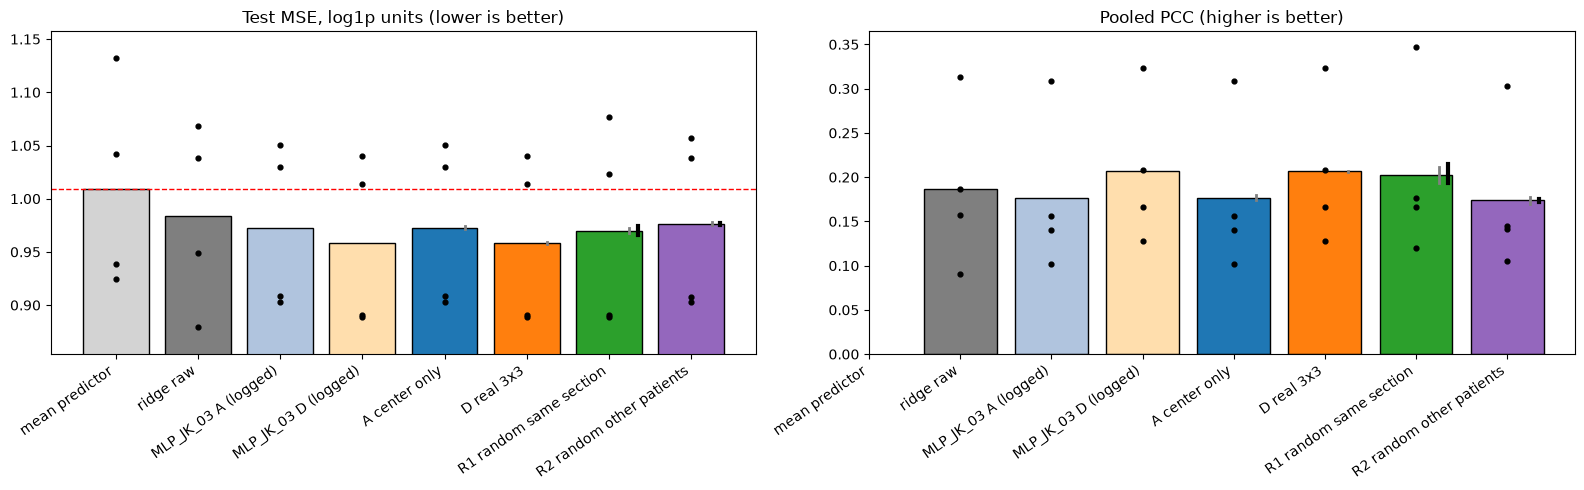

In [22]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    "MLP_JK_03 A (logged)": "lightsteelblue",
    "MLP_JK_03 D (logged)": "navajowhite",
    SETUP_NAMES["A"]: "tab:blue",
    SETUP_NAMES["D"]: "tab:orange",
    SETUP_NAMES["R1"]: "tab:green",
    SETUP_NAMES["R2"]: "tab:purple",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(model_order))
for ax, column, summary_column, label in [(axes[0], "MSE", "test_MSE", "MSE"), (axes[1], "PCC", "pooled_PCC", "PCC")]:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black")
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        row = summary[summary["model"] == model_name].iloc[0]
        if model_name in setup_names:
            middle = row[summary_column]
            seed_half = row[f"seed_{label}_range"] / 2
            ax.plot([i + 0.25, i + 0.25], [middle - seed_half, middle + seed_half], color="grey", linewidth=2)
            if not np.isnan(row[f"draw_{label}_min"]):
                ax.plot([i + 0.35, i + 0.35], [row[f"draw_{label}_min"], row[f"draw_{label}_max"]],
                        color="black", linewidth=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=35, ha="right")
axes[0].set_title("Test MSE, log1p units (lower is better)")
axes[1].set_title("Pooled PCC (higher is better)")
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores["MSE"].min()
high = fold_scores["MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

## Step 15. Save results and add them to the log

`all_results.csv` gets one row each for the mean predictor, ridge raw, A, D, R1 and R2 (R1 and R2 averaged over the 3 draws). The MLP_JK_03 reference rows aren't added again. If this notebook is run again, its old rows are replaced instead of duplicated. MLP_JK_Best is **not** changed: this is a control.

In [23]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
run_scores.to_csv(os.path.join(OUT_DIR, "run_scores.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
run_fold_scores.to_csv(os.path.join(OUT_DIR, "run_fold_scores.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "setups": SETUPS,
    "setup_names": SETUP_NAMES,
    "input_sizes": INPUT_SIZES,
    "draw_seeds": DRAW_SEEDS,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        if row["model"] in REFERENCE_ROWS.values():
            continue
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row["val_PCC"],
            "val_NRMSE": row["val_NRMSE"],
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                  condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date
MLP_JK_01             mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_01                  ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_01                    MLP raw      0.1721              0.1434 1.1382                1.0997   0.1525     1.1353 2026-11-06
MLP_JK_01        MLP center+mean-3x3      0.2160              0.1563 1.1141                1.0997   0.1495     1.1303 2026-11-06
MLP_JK_02             mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-06
MLP_JK_02                  ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-06
MLP_JK_02                    MLP raw      0.1767              0.1433 1.0806                1.0997

## Summary in plain words: do the real neighbors matter?

**Checks first**
- Ridge on raw embeddings reproduced Notebook 5 (pooled PCC 0.1868).
- Setup D reproduced MLP_JK_03's setup D exactly (test MSE 0.9584, pooled PCC 0.2064), so these rows are comparable with MLP_JK_03.
- The random neighbors behave as intended: every spot got exactly as many random spots as its real 3×3 neighborhood has; all R1 spots came from the same section; all R2 spots came from other patients; and no R2 draw crossed the train/test split.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Test MSE** (the loss) | Average squared difference between predicted and true expression (log1p), over all test spots and the 50 genes | Lower is better. Mean predictor = 1.009 |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots | 0 = no relation, 1 = perfect |
| **Within-patient PCC** | The same correlation inside one patient at a time | Higher is better. For patients with several sections, it also includes differences *between* that patient's sections |
| **NRMSE** | The error divided by the gene's spread | Lower is better; below the mean predictor (1.100) = better than guessing the average |
| **Validation PCC / NRMSE** | The same scores on held-out *training* patients (used for choosing; reported here for completeness) | Higher PCC, lower NRMSE |
| **Draw spread / seed spread** | How much a score moves between random draws of neighbors / between the 3 model seeds | A difference smaller than these could be luck |

### What we got

| Setup | Test MSE | Pooled PCC | Within-patient PCC | NRMSE | Validation PCC | Draw range (MSE / PCC) | Largest seed range (MSE / PCC) |
|---|---|---|---|---|---|---|---|
| mean predictor | 1.009 | — | — | 1.100 | — | — | — |
| ridge raw | 0.984 | 0.187 | 0.151 | 1.092 | — | — | — |
| **A** center only | 0.973 | 0.177 | 0.143 | 1.081 | 0.190 | — | 0.0035 / 0.006 |
| **D** real 3×3 | **0.958** | **0.206** | 0.158 | **1.071** | 0.208 | — | 0.0016 / 0.001 |
| **R1** random, same section | 0.970 | 0.202 | **0.171** | 1.080 | 0.221 | 0.966–0.974 / 0.194–0.215 | 0.0043 / 0.018 |
| **R2** random, other patients | 0.977 | 0.174 | 0.141 | 1.083 | 0.182 | 0.976–0.977 / 0.171–0.176 | 0.0029 / 0.008 |

### The three questions

**1. Does the real 3×3 (D) beat random same-section neighbors (R1)? For the loss, yes; for PCC, not clearly.**
- **Test MSE:** D is 0.011 lower than R1 on average, and lower than *every* R1 draw (by 0.008–0.016). That is larger than the draw spread (0.008) and the seed spread (≤ 0.004).
- **Where the MSE gain comes from:** it is concentrated in 2 folds (fold 0: −0.010, fold 1: −0.036). In folds 2 and 3, D and R1 tie (+0.0004 and 0.0000), so it doesn't hold in all 4 folds.
- **Pooled PCC:** D is only 0.004 higher. That is well inside the draw spread (0.021) and the seed spread (0.018), and one R1 draw (0.215) is even above D. So for ranking spots, the real neighbors add little beyond a random sample of the same section.
- **Conclusion:** the local neighborhood matters for getting the predicted *values* right (lower loss), but not clearly for the *order* of spots.

**2. Does R1 beat center only (A)? Yes for PCC, not for the loss, so part of the gain is slide/patient-level information.**
- **PCC:** pooled PCC is +0.026 higher, in all 4 folds, and every R1 draw is above A (by 0.017–0.038, more than A's seed spread of 0.006). Within-patient PCC is +0.028 higher, and validation PCC is higher too (0.221 vs. 0.190).
- **Test MSE:** only 0.003 lower on average, with mixed signs (lower in 3 of 4 folds, but much *higher* in fold 1: +0.027). Per draw it ranges from slightly worse than A to 0.007 better, so it is within the spread.
- **Why it works:** a random average over the same section is roughly a "what does this whole slide look like" summary. That tells the model something about the slide and the patient, which helps ranking but can also shift a whole test patient's predictions to the wrong level (as in fold 1).
- **Caveat on within-patient PCC:** R1's within-patient PCC (0.171) is the highest of all, but for patients with several sections this score also rewards getting the differences *between sections* right, which is exactly what a section-level average gives. It probably does not mean R1 ranks spots within a tissue better than D.

**3. Does R2 beat A? No: averaging in unrelated embeddings doesn't help.**
- R2 is slightly **worse** than A on the loss: test MSE 0.004 higher, worse for all 3 draws, and lower in only 1 of 4 folds. The size of that difference is about the same as the seed spread, so the honest reading is "no gain, possibly a small loss".
- Pooled PCC is about the same (−0.003, inside the spread), and validation PCC is lower (0.182 vs. 0.190).
- The gain from the window is **not** just a smoothing or "more embeddings" effect.

### Bottom line for the professor
Splitting D's gain over the center spot alone (test MSE −0.014, pooled PCC +0.030):
- **Averaging in random embeddings from other patients (R2):** no gain.
- **Same-section information (R1 vs. A):** most of the **PCC** gain (+0.026 of +0.030), but only about a fifth of the **loss** gain (−0.003 of −0.014).
- **The real local neighbors (D vs. R1):** most of the **loss** gain (−0.011 of −0.014), though only in 2 of 4 folds, and little extra PCC (+0.004, within noise).

In short, the window helps for two reasons: it gives the model a sense of the whole slide, which improves ranking, and the true local neighborhood makes the predicted values more accurate. It is not just averaging more embeddings.

This is a control, so MLP_JK_Best is unchanged.